# Hybrid QG + learned velocity correction: does it train, and what does it learn?

The 1.5-layer QG model of `qgsw-DI` advects potential vorticity with the
geostrophic velocity. QG-Net ([arXiv:1911.08856](https://arxiv.org/abs/1911.08856))
adds a correction $(\delta u, \delta v)$ to that velocity, predicted from SSH by
a CNN and trained end-to-end through the differentiable solver. This notebook
asks three questions on 475 days of NATL60 OSMOSIS SSH (a 128×128 box, about
450 km, at 1/20°):

1. **Does it train well?** Learning curves, multi-day skill against strong
   physics baselines, confidence intervals.
2. **What does the learned correction mean physically?** The obvious candidate
   is the first-order ageostrophic velocity
   $\mathbf u_a = f^{-1}\,\hat{\mathbf z}\times(\mathbf u_g\cdot\nabla)\mathbf u_g$,
   whose along-stream part is the gradient-wind correction: flow round cyclones
   is slower than geostrophic, flow round anticyclones faster.
3. **How much of the gain survives against the best physics-only model?**

Models compared, all on the same test days:

| name | what it is | trainable parameters |
|---|---|---|
| persistence | SSH(t+n) = SSH(t) | 0 |
| QG, c=1.5 | the original configuration (`c=1.5 m/s`, `snu=0`) | 0 |
| QG, tuned | `c` and `snu` grid-searched on training days | 0 (2 tuned) |
| QG + γ·gradient wind | tuned QG plus $\gamma\,\mathbf u_a$, γ learned through the solver | 1 |
| QG + ResUNet (original) | the network this notebook used before: SSH standardised per image, GroupNorm | 125 k |
| QG + ResUNet (amplitude-aware) | same U-Net, fixed SSH scale, no normalisation layers | 125 k |
| QG + uniform drift | a constant velocity (U, V) added everywhere, learned through the solver | 2 |

The hybrids all sit on top of the tuned QG, so every gain is measured against
the best physics-only model rather than an untuned one.

**Running it.** With `RETRAIN = False` the trained weights in `checkpoints/`
are loaded when present (otherwise the models are trained, about 1.5 h each on
an Apple M2 CPU, or about 6× faster on its GPU). The same training can be
launched from a terminal, e.g.
`python qgnet_lab.py train resunet_amp --device mps --batch 16 --checkpoint`.
All experiment code lives in [`qgnet_lab.py`](qgnet_lab.py), next to this
notebook; `load_patch` takes the file, variable names and box of another
dataset.

## Key findings

Numbers are from the executed run below (53 test start days, Aug–Sep 2013; 95 % bootstrap intervals).

1. **It trains, and the gain is real but small.** Both ResUNet hybrids beat
   *tuned* QG at every lead from 1 to 5 days: −2.4 % [−3.3, −1.5] and
   −1.8 % [−2.3, −1.3] RMSE at day 3, winning on 75 % of start days. For scale,
   QG beats persistence by 22 % at day 3, and simply tuning `c` and `snu` is
   worth 2.4 %.
2. **The networks learned a uniform drift.** A 2-parameter model, a constant
   velocity (U, V) = (−0.81, +0.43) cm/s added everywhere, matches them
   (−2.0 % [−2.6, −1.4]). Keeping only the interior mean of each network's
   correction reproduces its gain (−1.5 %, −1.9 %); keeping only its spatial
   pattern gives nothing (+0.5 %, +0.2 %).
3. **No local ageostrophic physics was found.** Once the drift is removed,
   gradient wind, viscosity, rescaling and cross-stream deflection explain at
   most 3 % of what is left. The learned gradient-wind amplitude is γ = 0.44,
   worth 0.0 %. The flow here has an rms Rossby number of only about 0.1 at
   1/20°, so the first-order ageostrophic correction is genuinely small.
4. **The drift is physical, not an artefact.**
   * Integrating on a 256×168 domain gives the same gain in the same central
     cells (−3.5 % at day 3), so the open boundary is not the cause.
   * The best drift on a (U, V) grid is the same on training and test days:
     about 1 cm/s westward.
5. **What it means:** the 1.5-layer QG moves eddies westward too slowly, by
   about 0.6–1 cm/s (0.5–0.9 km/day), on top of its own long-Rossby speed of
   ≈0.5 cm/s. That matches the classic finding that observed westward
   propagation outruns standard linear theory at mid-latitudes. Raising `c`
   cannot fix it, because `c` also sets the deformation radius. The gain sits
   at eddy scales: day-3 error power falls by 10–20 % at 100–200 km. At the
   domain scale (> 300 km) it rises, as you would expect from translating
   everything at one speed.
6. **The amplitude-aware redesign did not help.** The original ResUNet
   (per-image SSH standardisation, GroupNorm) is as good or better; with a
   correction that is mostly a constant, amplitude awareness has nothing to
   act on.

## 1. Setup

In [1]:
import json
import sys
import time
from pathlib import Path

import numpy as np
import torch
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm

NB_DIR = Path.cwd()
if not (NB_DIR / "qgnet_lab.py").exists():
    NB_DIR = Path.cwd() / "QGNet_Pytorch" / "notebooks"
sys.path.insert(0, str(NB_DIR))
import qgnet_lab as L

RETRAIN = False          # True: retrain every model even if a checkpoint exists
torch.set_num_threads(8)

# Reference palette: fixed categorical order, recessive chrome, blue-grey-red diverging maps.
INK, INK2, MUTED, GRID = "#0b0b0b", "#52514e", "#898781", "#e1e0d9"
SLOT = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
STYLE = {   # model -> (colour, line style, label)
    "persistence": (MUTED, ":", "persistence"),
    "qg_default": (MUTED, "--", "QG, c=1.5"),
    "qg_tuned": (SLOT[0], "-", "QG, tuned"),
    "resunet_orig": (SLOT[1], "-", "QG + ResUNet (original)"),
    "gradwind_gamma": (SLOT[2], "-", "QG + γ·gradient wind"),
    "resunet_amp": (SLOT[3], "-", "QG + ResUNet (amplitude-aware)"),
    "uniform_drift": (SLOT[4], "-", "QG + uniform drift (2 params)"),
}
DIVERGING = LinearSegmentedColormap.from_list(
    "bgr", ["#104281", "#3987e5", "#9ec5f4", "#f0efec", "#f4a6a5", "#e34948", "#8f1f1f"])
SEQUENTIAL = LinearSegmentedColormap.from_list(
    "blue", ["#fcfcfb", "#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"])
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "savefig.facecolor": "#fcfcfb",
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": INK2, "text.color": INK,
    "xtick.color": MUTED, "ytick.color": MUTED, "axes.grid": True, "grid.color": GRID,
    "grid.linewidth": 0.6, "axes.spines.top": False, "axes.spines.right": False,
    "lines.linewidth": 2.0, "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold",
    "legend.frameon": False, "figure.dpi": 110,
})


def label_line_end(ax, x, y, text, color):
    ax.annotate(text, (x, y), xytext=(6, 0), textcoords="offset points",
                va="center", fontsize=8.5, color=INK2)

In [2]:
data = L.load_patch()
idx = L.splits(len(data["ssh"]))
dates = data["time"].astype("datetime64[D]")
case_default = L.Case(data, c=L.C_DEFAULT, snu=0.0)
case = L.Case(data, c=L.C_TUNED, snu=L.SNU_TUNED)    # the physics the hybrids sit on
grd = case.grd
f0_mean = float(grd.f0.mean())
dx_mean = float(grd.dx.mean())
print(f"{len(dates)} daily fields, {dates[0]} -> {dates[-1]}, patch {grd.ny}x{grd.nx}, "
      f"dx ~ {dx_mean/1e3:.1f} km, f0 ~ {f0_mean:.2e} s^-1, "
      f"Rossby radius c/f ~ {L.C_DEFAULT/f0_mean/1e3:.0f} km (c=1.5) / {L.C_TUNED/f0_mean/1e3:.0f} km (c=2)")
for k, v in idx.items():
    print(f"{k:5s}: {len(v):3d} start days, {dates[v[0]]} -> {dates[v[-1]]}")

475 daily fields, 2012-06-14 -> 2013-10-01, patch 128x128, dx ~ 3.7 km, f0 ~ 1.12e-04 s^-1, Rossby radius c/f ~ 13 km (c=1.5) / 18 km (c=2)
train: 360 start days, 2012-06-14 -> 2013-06-08
val  :  47 start days, 2013-06-14 -> 2013-07-30
test :  53 start days, 2013-08-05 -> 2013-09-26


## 2. The flow regime

Before any learning: how far is this flow from QG? The geostrophic Rossby
number $\zeta_g/f$ measures it. QG assumes $|\zeta/f|\ll 1$; the gradient-wind
correction is first order in it.

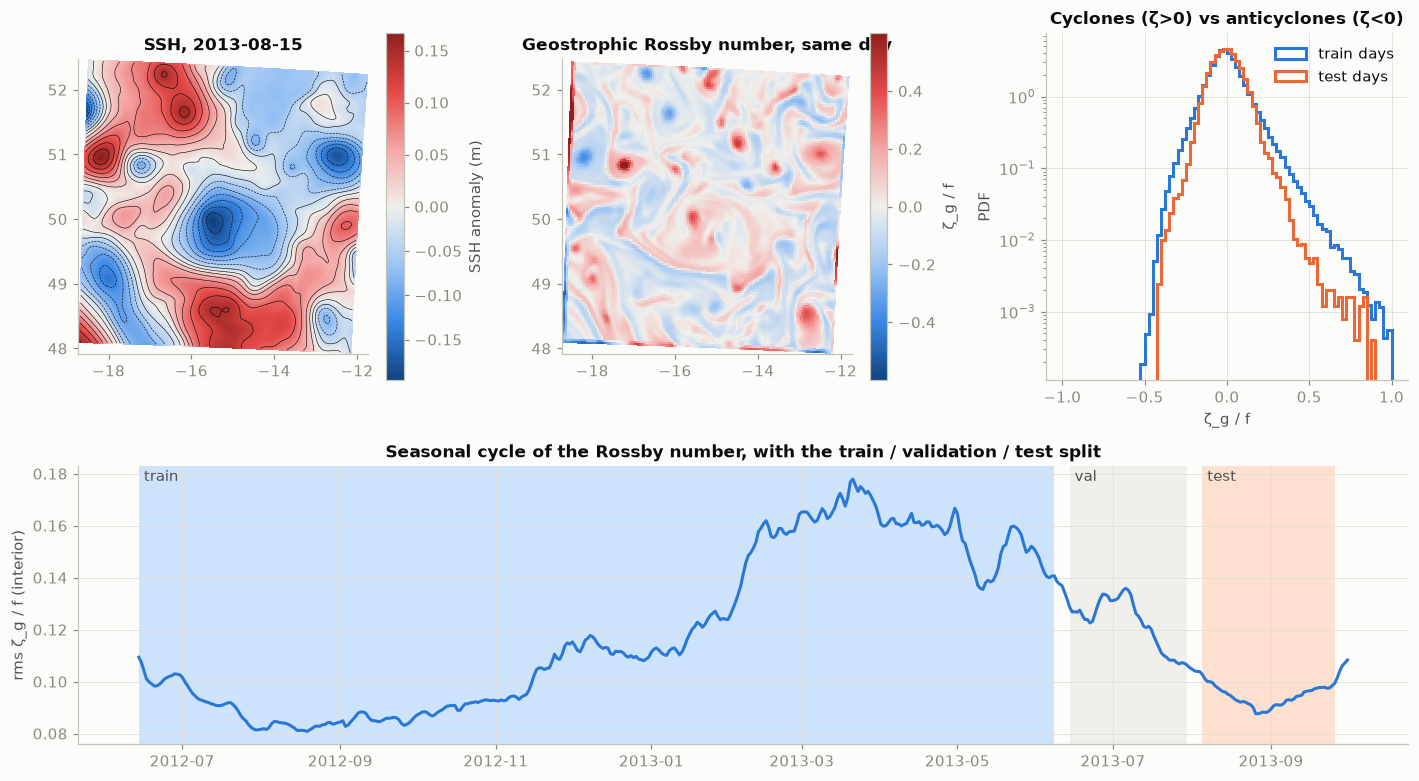

rms Rossby number: train 0.119, val 0.123, test 0.094; 1% of cells have |ζ/f| > 0.3 on the day shown


In [3]:
ro_rms, ke = [], []
for t in range(len(dates)):
    d = L.diagnostics(data["ssh"][t], grd)
    w = L.interior_window((grd.ny, grd.nx))
    ro_rms.append(np.sqrt(np.mean((d["zeta"] / d["f"])[w] ** 2)))
    ke.append(0.5 * np.mean((d["ug"] ** 2 + d["vg"] ** 2)[w]))
ro_rms, ke = np.array(ro_rms), np.array(ke)

day_show = int(idx["test"][10])
d_show = L.diagnostics(data["ssh"][day_show], grd)
ro_show = d_show["zeta"] / d_show["f"]

fig = plt.figure(figsize=(13, 7.2))
gs = fig.add_gridspec(2, 3, height_ratios=[1.25, 1])
ax = fig.add_subplot(gs[0, 0])
h = data["ssh"][day_show]
im = ax.pcolormesh(data["lon"], data["lat"], h - np.nanmean(h), cmap=DIVERGING,
                   norm=TwoSlopeNorm(0), shading="auto")
ax.contour(data["lon"], data["lat"], h, 14, colors=INK, linewidths=0.4)
fig.colorbar(im, ax=ax, label="SSH anomaly (m)")
ax.set_title(f"SSH, {dates[day_show]}")
ax.set_aspect(1 / np.cos(np.deg2rad(data["lat"].mean())))
ax.grid(False)

ax = fig.add_subplot(gs[0, 1])
im = ax.pcolormesh(data["lon"], data["lat"], ro_show, cmap=DIVERGING,
                   norm=TwoSlopeNorm(0, -0.6, 0.6), shading="auto")
fig.colorbar(im, ax=ax, label="ζ_g / f")
ax.set_title("Geostrophic Rossby number, same day")
ax.set_aspect(1 / np.cos(np.deg2rad(data["lat"].mean())))
ax.grid(False)

ax = fig.add_subplot(gs[0, 2])
bins = np.linspace(-1, 1, 81)
for name, sl, col in (("train", idx["train"], SLOT[0]), ("test", idx["test"], SLOT[1])):
    vals = np.concatenate([(L.diagnostics(data["ssh"][t], grd)["zeta"] / f0_mean)[8:-8, 8:-8].ravel()
                           for t in sl[::7]])
    ax.hist(vals, bins, density=True, histtype="step", color=col, lw=2, label=f"{name} days")
ax.set_yscale("log")
ax.set_xlabel("ζ_g / f")
ax.set_ylabel("PDF")
ax.set_title("Cyclones (ζ>0) vs anticyclones (ζ<0)")
ax.legend()

ax = fig.add_subplot(gs[1, :])
for name, sl, shade in (("train", idx["train"], "#cde2fb"), ("val", idx["val"], "#f0efec"),
                        ("test", idx["test"], "#fde0d0")):
    ax.axvspan(dates[sl[0]], dates[sl[-1]], color=shade, lw=0)
    ax.text(dates[sl[0]], 0.99, f" {name}", transform=ax.get_xaxis_transform(), va="top", color=INK2)
ax.plot(dates, ro_rms, color=SLOT[0])
ax.set_ylabel("rms ζ_g / f (interior)")
ax.set_title("Seasonal cycle of the Rossby number, with the train / validation / test split")
fig.tight_layout()
plt.show()
print(f"rms Rossby number: train {ro_rms[idx['train']].mean():.3f}, "
      f"val {ro_rms[idx['val']].mean():.3f}, test {ro_rms[idx['test']].mean():.3f}; "
      f"{100*np.mean(np.abs(ro_show[8:-8, 8:-8]) > 0.3):.0f}% of cells have |ζ/f| > 0.3 on the day shown")

## 3. Physics baselines first

A learned correction can only be credited with what the physics cannot do
by itself. Three checks before any training:

* **time step**: the hybrids use `dt = 1200 s` to halve the training cost;
* **inversion**: `pv2h` does a single steepest-descent step per time step by
  design; does a converged inversion change the forecast?
* **phase speed and diffusion**: `c` and `snu` are grid-searched on training
  days (1–3 day RMSE).

In [4]:
probe = idx["val"][::4]
rows = []
for dt in (600, 1200):
    r = np.mean([float(case_default.mse(case_default.forecast(s, 1, dt=dt), case_default.target(s, 1))[0].sqrt())
                 for s in probe])
    rows.append((f"QG c=1.5, dt={dt}", r))
with L.inversion_iterations(25):
    r = np.mean([float(case_default.mse(case_default.forecast(s, 1), case_default.target(s, 1))[0].sqrt())
                 for s in probe])
rows.append(("QG c=1.5, dt=1200, converged inversion (25 CG iterations)", r))
for name, r in rows:
    print(f"{name:60s} 1-day RMSE {1e3*r:.3f} mm")

QG c=1.5, dt=600                                             1-day RMSE 6.188 mm
QG c=1.5, dt=1200                                            1-day RMSE 6.189 mm
QG c=1.5, dt=1200, converged inversion (25 CG iterations)    1-day RMSE 6.188 mm


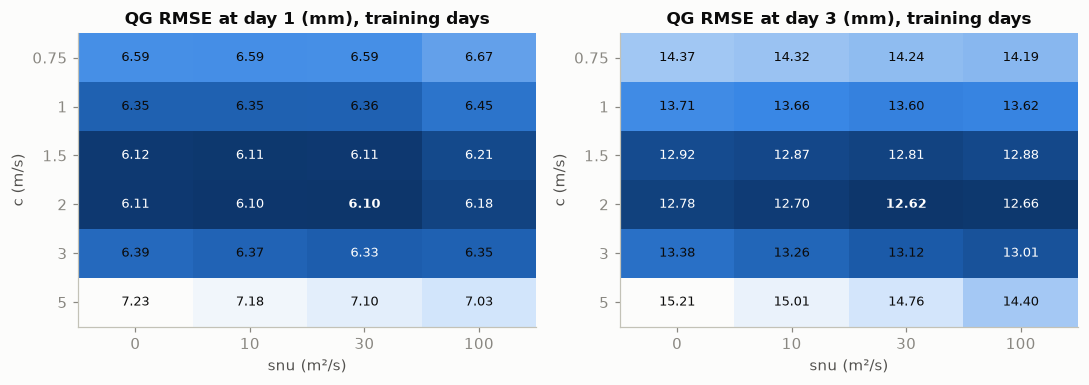

best at day 3: c=2.0, snu=30.0 (used: c=2.0, snu=30.0); gain over c=1.5, snu=0: 0.4% at day 1, 2.3% at day 3


In [5]:
tuning_file = L.CHECKPOINT_DIR / "qg_tuning.json"
C_GRID = [0.75, 1.0, 1.5, 2.0, 3.0, 5.0]
SNU_GRID = [0.0, 10.0, 30.0, 100.0]
if tuning_file.exists() and not RETRAIN:
    tuning = json.loads(tuning_file.read_text())
else:
    tuning, t0 = {}, time.perf_counter()
    tune_case = L.Case(data)
    for c in C_GRID:
        for snu in SNU_GRID:
            tune_case.set_physics(c, snu)
            tuning[f"{c}_{snu}"] = L.rmse_by_lead(tune_case, idx["train"][::6], days=3).mean(0).tolist()
    L.CHECKPOINT_DIR.mkdir(exist_ok=True)
    tuning_file.write_text(json.dumps(tuning))
    print(f"tuning took {time.perf_counter()-t0:.0f} s")

grid = np.array([[tuning[f"{c}_{s}"] for s in SNU_GRID] for c in C_GRID])   # (c, snu, lead)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
for ax, lead in zip(axes, (0, 2)):
    z = 1e3 * grid[..., lead]
    im = ax.imshow(z, cmap=SEQUENTIAL.reversed(), aspect="auto")
    for i in range(len(C_GRID)):
        for j in range(len(SNU_GRID)):
            best = z[i, j] == z.min()
            ax.text(j, i, f"{z[i, j]:.2f}", ha="center", va="center", fontsize=8.5,
                    color="#ffffff" if z[i, j] < np.percentile(z, 35) else INK,
                    fontweight="bold" if best else "normal")
    ax.set_xticks(range(len(SNU_GRID)), [f"{s:g}" for s in SNU_GRID])
    ax.set_yticks(range(len(C_GRID)), [f"{c:g}" for c in C_GRID])
    ax.set_xlabel("snu (m²/s)")
    ax.set_ylabel("c (m/s)")
    ax.set_title(f"QG RMSE at day {lead+1} (mm), training days")
    ax.grid(False)
fig.tight_layout()
plt.show()
i, j = np.unravel_index(np.argmin(grid[..., 2]), grid.shape[:2])
print(f"best at day 3: c={C_GRID[i]}, snu={SNU_GRID[j]} (used: c={L.C_TUNED}, snu={L.SNU_TUNED}); "
      f"gain over c=1.5, snu=0: {100*(1-grid[i, j, 0]/grid[2, 0, 0]):.1f}% at day 1, "
      f"{100*(1-grid[i, j, 2]/grid[2, 0, 2]):.1f}% at day 3")

## 4. Training

Each epoch draws 120 training start days, rolls the hybrid out for *k* days
(curriculum k = 1 → 2 → 3 over 12 epochs, learning rate halved at each step)
and minimises the mean daily SSH MSE over interior water; gradients flow
through every solver step. The checkpoint with the best 1-day validation MSE
is kept. The correction is re-evaluated every model hour.

In [6]:
MODEL_NAMES = ["resunet_orig", "gradwind_gamma", "resunet_amp", "uniform_drift"]
NETS = ["resunet_orig", "resunet_amp"]
models, hists = {}, {}
for name in MODEL_NAMES:
    if (L.CHECKPOINT_DIR / f"{name}.pt").exists() and not RETRAIN:
        models[name], hists[name] = L.load_trained(name, case)
    else:
        models[name], hists[name] = L.train(name, case, idx)
    cfg = hists[name]["config"]
    print(f"{name:15s} {cfg['n_params']:7d} params, best val epoch "
          f"{min(hists[name]['epochs'], key=lambda e: e['val_mse_1d'])['epoch']}, "
          f"trained in {hists[name]['epochs'][-1]['seconds']/60:.0f} min")
print(f"learned gamma = {float(models['gradwind_gamma'].gamma):.3f}")
U, V = models["uniform_drift"].uv.tolist()
print(f"learned uniform drift U = {100*U:+.2f} cm/s (east), V = {100*V:+.2f} cm/s (north)")

resunet_orig     125218 params, best val epoch 12, trained in 104 min
gradwind_gamma        1 params, best val epoch 7, trained in 33 min
resunet_amp      124578 params, best val epoch 10, trained in 100 min
uniform_drift         2 params, best val epoch 6, trained in 26 min
learned gamma = 0.444
learned uniform drift U = -0.81 cm/s (east), V = +0.43 cm/s (north)


/var/folders/fh/hzjykwm53hqdtqwhsjzmjwtw0000gn/T/ipykernel_88480/3757214237.py:13: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at /Users/runner/work/pytorch/pytorch/torch/csrc/autograd/generated/python_variable_methods.cpp:821.)
  print(f"learned gamma = {float(models['gradwind_gamma'].gamma):.3f}")


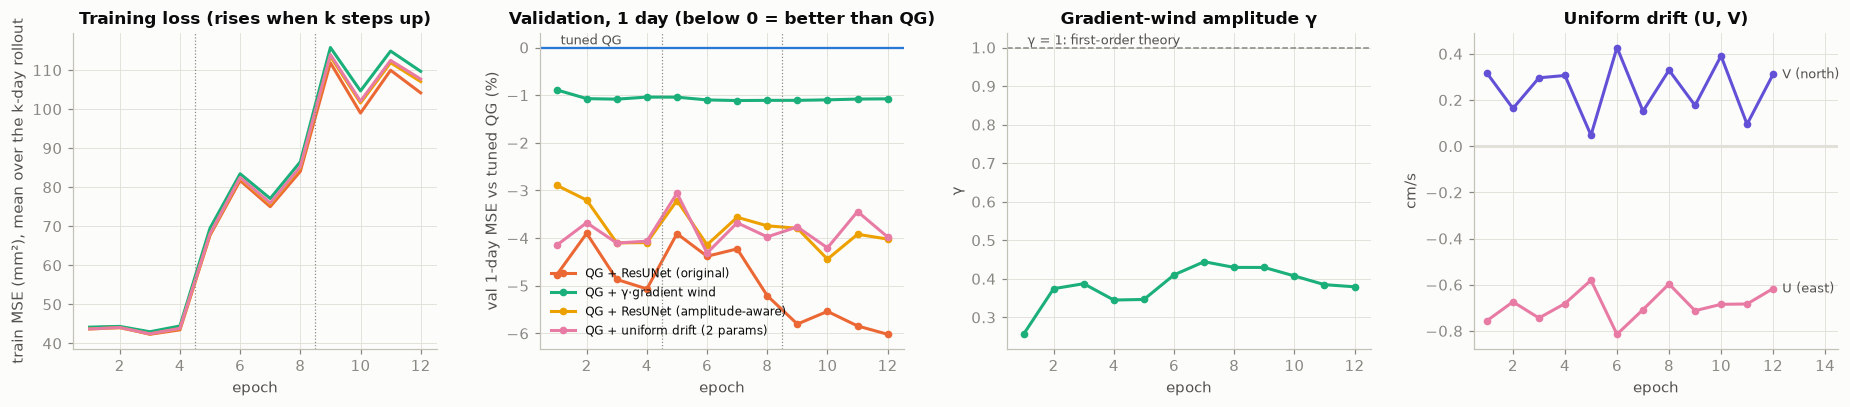

In [7]:
qg_val = np.mean([float(case.mse(case.forecast(s, 1), case.target(s, 1))[0]) for s in idx["val"]])
fig, axes = plt.subplots(1, 4, figsize=(17, 3.8))
for name in MODEL_NAMES:
    col, ls, lab = STYLE[name]
    ep = [e["epoch"] for e in hists[name]["epochs"]]
    axes[0].plot(ep, [1e6 * e["train_mse"] for e in hists[name]["epochs"]], color=col, ls=ls, label=lab)
    axes[1].plot(ep, [100 * (e["val_mse_1d"] / qg_val - 1) for e in hists[name]["epochs"]],
                 color=col, ls=ls, marker="o", ms=4, label=lab)
for ax in axes[:2]:
    for e in hists[MODEL_NAMES[0]]["epochs"]:
        if e["epoch"] > 1 and e["k"] != hists[MODEL_NAMES[0]]["epochs"][e["epoch"] - 2]["k"]:
            ax.axvline(e["epoch"] - 0.5, color=MUTED, lw=0.8, ls=":")
    ax.set_xlabel("epoch")
axes[0].set_ylabel("train MSE (mm²), mean over the k-day rollout")
axes[0].set_title("Training loss (rises when k steps up)")
axes[1].axhline(0, color=STYLE["qg_tuned"][0], lw=1.5)
axes[1].text(1, 0, " tuned QG", color=INK2, va="bottom", fontsize=8.5)
axes[1].set_ylabel("val 1-day MSE vs tuned QG (%)")
axes[1].set_title("Validation, 1 day (below 0 = better than QG)")
axes[1].legend(fontsize=8)
g = [e["gamma"] for e in hists["gradwind_gamma"]["epochs"]]
axes[2].plot(range(1, len(g) + 1), g, color=STYLE["gradwind_gamma"][0], marker="o", ms=4)
axes[2].axhline(1, color=MUTED, ls="--", lw=1)
axes[2].text(1, 1, " γ = 1: first-order theory", color=INK2, va="bottom", fontsize=8.5)
axes[2].set_xlabel("epoch")
axes[2].set_ylabel("γ")
axes[2].set_title("Gradient-wind amplitude γ")
uv = np.array([e["uv"] for e in hists["uniform_drift"]["epochs"]])
for comp, lab, col in ((0, "U (east)", SLOT[4]), (1, "V (north)", SLOT[6])):
    axes[3].plot(range(1, len(uv) + 1), 100 * uv[:, comp], color=col, marker="o", ms=4)
    label_line_end(axes[3], len(uv), 100 * uv[-1, comp], lab, col)
axes[3].axhline(0, color=GRID)
axes[3].set_xlim(0.5, len(uv) + 2.5)
axes[3].set_xlabel("epoch")
axes[3].set_ylabel("cm/s")
axes[3].set_title("Uniform drift (U, V)")
fig.tight_layout()
plt.show()

## 5. Forecast skill on the test period

53 test start days, each forecast 5 days ahead (training never went past 3).
Shaded bands are 95 % bootstrap intervals over start days. The right panel
is the paired difference to tuned QG, which removes the day-to-day variability
the models share.

forecasts took 353 s


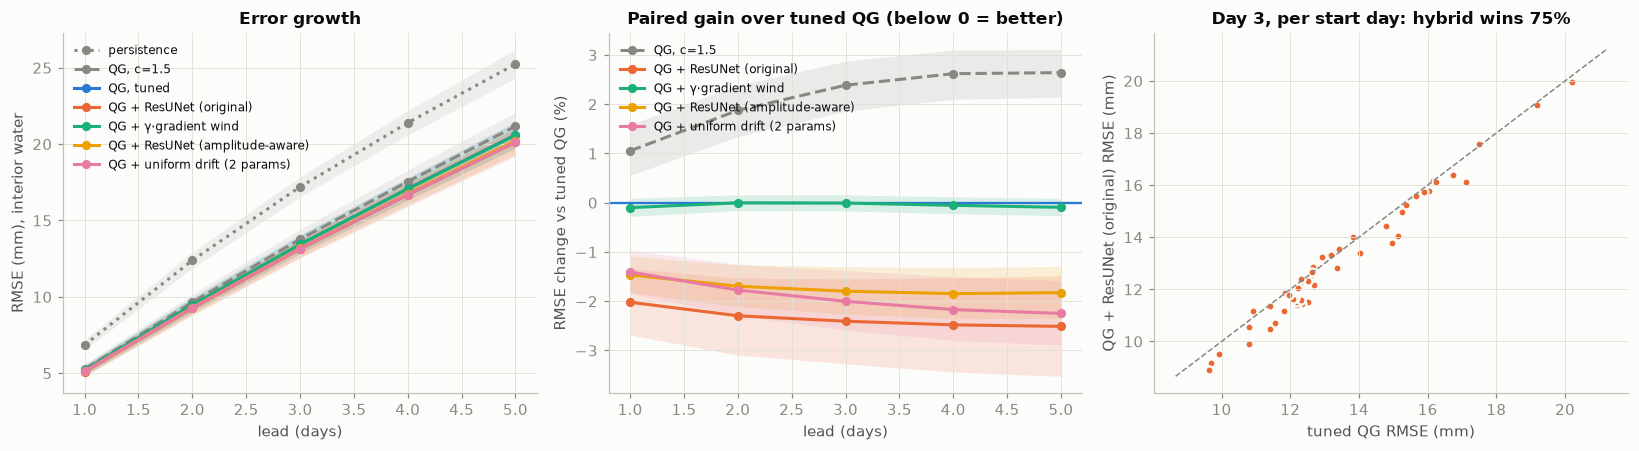

model                             day 1  day 2  day 3  day 4  day 5   (mean RMSE, mm)
persistence                        6.86  12.39  17.20  21.40  25.24
QG, c=1.5                          5.26   9.65  13.77  17.54  21.17
QG, tuned                          5.20   9.46  13.43  17.07  20.60
QG + ResUNet (original)            5.10   9.25  13.13  16.68  20.12
QG + γ·gradient wind               5.20   9.46  13.43  17.07  20.59
QG + ResUNet (amplitude-aware)     5.12   9.29  13.19  16.75  20.22
QG + uniform drift (2 params)      5.13   9.28  13.16  16.70  20.13

paired change vs tuned QG, % [95% CI]
QG, c=1.5                          +1.1 [+0.6,+1.6]   +1.9 [+1.3,+2.4]   +2.4 [+1.9,+2.9]   +2.6 [+2.1,+3.1]   +2.6 [+2.1,+3.1]
QG + ResUNet (original)            -2.0 [-2.7,-1.3]   -2.3 [-3.1,-1.5]   -2.4 [-3.3,-1.5]   -2.5 [-3.4,-1.5]   -2.5 [-3.5,-1.5]
QG + γ·gradient wind               -0.1 [-0.3,+0.1]   -0.0 [-0.2,+0.2]   -0.0 [-0.2,+0.2]   -0.1 [-0.2,+0.1]   -0.1 [-0.3,+0.1]
QG + ResUNet (a

In [8]:
t0 = time.perf_counter()
test = idx["test"]
truth = L.targets_all(case, test)
preds = {
    "persistence": L.forecast_all(case, test, persistence=True),
    "qg_default": L.forecast_all(case_default, test),
    "qg_tuned": L.forecast_all(case, test),
}
for name in MODEL_NAMES:
    preds[name] = L.forecast_all(case, test, models[name])
act = case.active.numpy()
rmse = {k: np.sqrt(np.mean((p - truth)[..., act] ** 2, axis=-1)) for k, p in preds.items()}  # (start, lead)
print(f"forecasts took {time.perf_counter()-t0:.0f} s")

leads = np.arange(1, L.MAX_LEAD + 1)
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
ax = axes[0]
for k, r in rmse.items():
    col, ls, lab = STYLE[k]
    lo, hi = L.bootstrap_ci(r)
    ax.fill_between(leads, 1e3 * lo, 1e3 * hi, color=col, alpha=0.12, lw=0)
    ax.plot(leads, 1e3 * r.mean(0), color=col, ls=ls, marker="o", ms=5, label=lab)
ax.legend(fontsize=8)
ax.set_xlabel("lead (days)")
ax.set_ylabel("RMSE (mm), interior water")
ax.set_title("Error growth")

ax = axes[1]
base = rmse["qg_tuned"]
ax.axhline(0, color=STYLE["qg_tuned"][0], lw=1.5)
for k in ["qg_default"] + MODEL_NAMES:
    col, ls, lab = STYLE[k]
    rel = 100 * (rmse[k] / base - 1)
    lo, hi = L.bootstrap_ci(rel)
    ax.fill_between(leads, lo, hi, color=col, alpha=0.15, lw=0)
    ax.plot(leads, rel.mean(0), color=col, ls=ls, marker="o", ms=5, label=lab)
ax.set_xlabel("lead (days)")
ax.set_ylabel("RMSE change vs tuned QG (%)")
ax.set_title("Paired gain over tuned QG (below 0 = better)")
ax.legend(fontsize=8)

ax = axes[2]
lead_i = 2
best_net = min(NETS, key=lambda k: rmse[k][:, lead_i].mean())
ax.scatter(1e3 * base[:, lead_i], 1e3 * rmse[best_net][:, lead_i], s=28, color=STYLE[best_net][0],
           edgecolor="#fcfcfb", linewidth=1.5)
lim = [1e3 * base[:, lead_i].min() * 0.9, 1e3 * base[:, lead_i].max() * 1.05]
ax.plot(lim, lim, color=MUTED, lw=1, ls="--")
win = np.mean(rmse[best_net][:, lead_i] < base[:, lead_i])
ax.set_xlabel("tuned QG RMSE (mm)")
ax.set_ylabel(f"{STYLE[best_net][2]} RMSE (mm)")
ax.set_title(f"Day {lead_i+1}, per start day: hybrid wins {100*win:.0f}%")
fig.tight_layout()
plt.show()

print(f"{'model':32s}" + "".join(f"  day {l}" for l in leads) + "   (mean RMSE, mm)")
for k, r in rmse.items():
    print(f"{STYLE[k][2]:32s}" + "".join(f"  {1e3*v:5.2f}" for v in r.mean(0)))
print("\npaired change vs tuned QG, % [95% CI]")
for k in ["qg_default"] + MODEL_NAMES:
    rel = 100 * (rmse[k] / base - 1)
    lo, hi = L.bootstrap_ci(rel)
    print(f"{STYLE[k][2]:32s}" + "".join(f"  {m:+5.1f} [{a:+.1f},{b:+.1f}]" for m, a, b in zip(rel.mean(0), lo, hi)))

### Where in space and in scale is the error reduced?

If the gain came from the open boundary (SSH there is frozen at its initial
value), it would sit along the edges. The maps below average the day-3 squared
error reduction over all test starts; the spectrum shows which scales are
fixed.

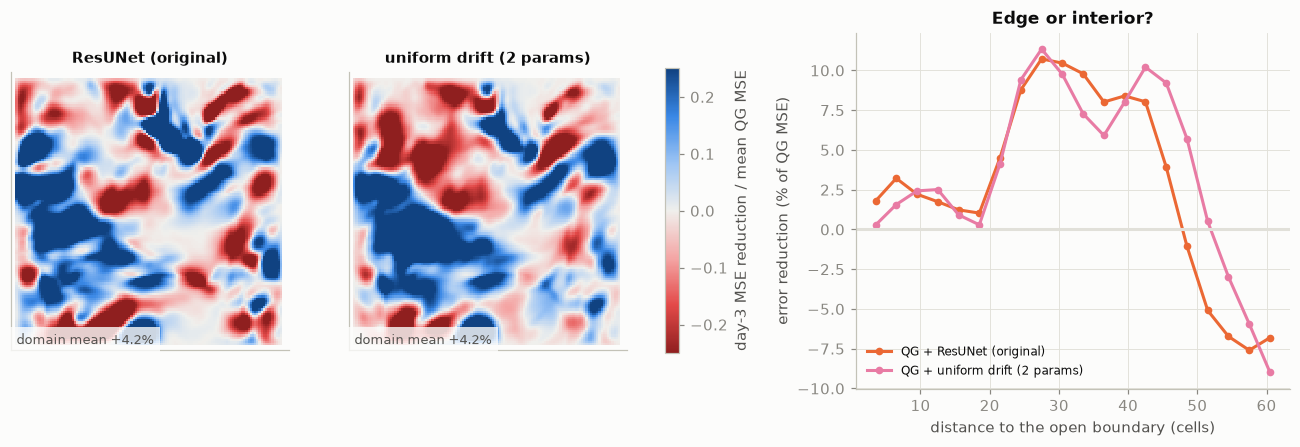

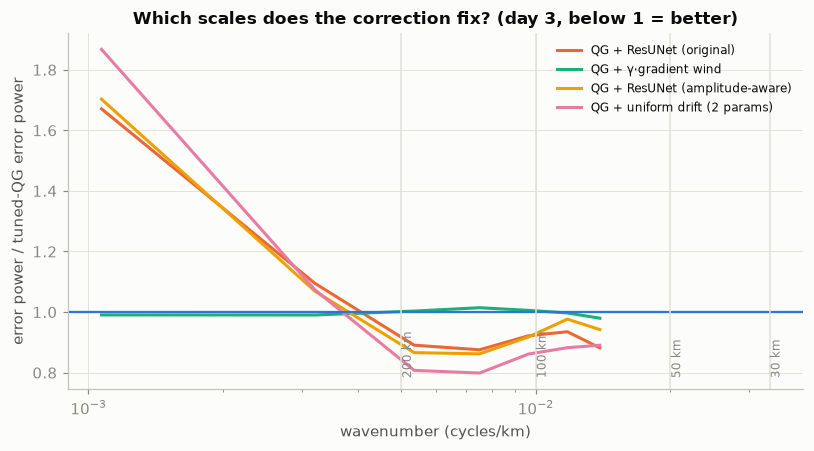

In [9]:
lead_i = 2
mse_map = {k: np.mean((preds[k][:, lead_i] - truth[:, lead_i]) ** 2, axis=0) for k in preds}
norm = np.mean(mse_map["qg_tuned"][act])
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2), gridspec_kw={"width_ratios": [1, 1, 1.25]})
vm = 0.25
for ax, k in zip(axes[:2], [best_net, "uniform_drift"]):
    gain = (mse_map["qg_tuned"] - mse_map[k]) / norm
    gain[~act] = np.nan
    im = ax.pcolormesh(gain, cmap=DIVERGING.reversed(), norm=TwoSlopeNorm(0, -vm, vm), shading="auto")
    ax.set_title(STYLE[k][2].replace("QG + ", ""), fontsize=9.5)
    ax.set_aspect("equal"); ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
    ax.text(0.02, 0.02, f"domain mean {100*np.nanmean(gain):+.1f}%", transform=ax.transAxes, fontsize=8.5,
            color=INK2, bbox=dict(fc="#fcfcfb", ec="none", alpha=0.8))
fig.colorbar(im, ax=axes[:2], shrink=0.8, label="day-3 MSE reduction / mean QG MSE")
ax = axes[2]
dist = L.distance_to_border((grd.ny, grd.nx))
dedges = np.arange(2, 64, 3)
for k in [best_net, "uniform_drift"]:
    gain = (mse_map["qg_tuned"] - mse_map[k]) / norm
    y = L.binned(dist[act].astype(float), gain[act], dedges)
    ax.plot(0.5 * (dedges[1:] + dedges[:-1]), 100 * y, color=STYLE[k][0], marker="o", ms=4, label=STYLE[k][2])
ax.axhline(0, color=GRID)
ax.set_xlabel("distance to the open boundary (cells)")
ax.set_ylabel("error reduction (% of QG MSE)")
ax.set_title("Edge or interior?")
ax.legend(fontsize=8)
plt.show()

def err_spec(k):
    return np.mean([L.radial_spectrum(preds[k][i, lead_i] - truth[i, lead_i], dx_mean)[1]
                    for i in range(len(test))], axis=0)


kk, _ = L.radial_spectrum(truth[0, 0], dx_mean)
spec_qg = err_spec("qg_tuned")
sig = np.mean([L.radial_spectrum(truth[i, lead_i], dx_mean)[1] for i in range(len(test))], axis=0)
energetic = sig > 1e-3 * sig.max()      # scales that carry the SSH variance
fig, ax = plt.subplots(figsize=(7.5, 4.2))
for k in MODEL_NAMES:
    col, ls, lab = STYLE[k]
    ax.semilogx(1e3 * kk[energetic], (err_spec(k) / spec_qg)[energetic], color=col, ls=ls, label=lab)
ax.axhline(1, color=STYLE["qg_tuned"][0], lw=1.5)
for L_km in (200, 100, 50, 30):
    ax.axvline(1 / L_km, color=GRID, lw=1)
    ax.text(1 / L_km, 0.02, f" {L_km} km", rotation=90, va="bottom", color=MUTED, fontsize=8,
            transform=ax.get_xaxis_transform())
ax.set_xlabel("wavenumber (cycles/km)")
ax.set_ylabel("error power / tuned-QG error power")
ax.set_title("Which scales does the correction fix? (day 3, below 1 = better)")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

## 6. What did the network learn?

The learned correction is evaluated on every test day and compared with
candidate physical terms built from the geostrophic flow, all at cell
centres and at least 8 cells from the open boundary:

* $\mathbf u_g$: a pure rescaling of the geostrophic flow (equivalently of $g/f$);
* $\hat{\mathbf z}\times\mathbf u_g$: a cross-stream (Ekman-like) deflection;
* $\nabla^2\mathbf u_g$: a viscous smoothing;
* $\mathbf u_a = f^{-1}\hat{\mathbf z}\times(\mathbf u_g\cdot\nabla)\mathbf u_g$:
  the first-order ageostrophic, gradient-wind correction.

Three tests: (a) maps, (b) the gradient-wind signature: the along-stream
fraction $\alpha=\delta\mathbf u\cdot\mathbf u_g/|\mathbf u_g|^2$ should fall with
$\zeta/f$ with slope about −½ (for solid-body rotation, gradient wind gives
$\alpha\approx-\zeta/2f$), (c) amplitude scaling: an ageostrophic
correction grows like $|\mathbf u_g|^2$; a network that cannot see the flow's
amplitude cannot reproduce that.

/Users/redouanelguensat/Desktop/QGNet/qgsw-DI/QGNet_Pytorch/notebooks/qgnet_lab.py:703: RuntimeWarning: invalid value encountered in divide
  return (cu * ug + cv * vg) / (ug ** 2 + vg ** 2)


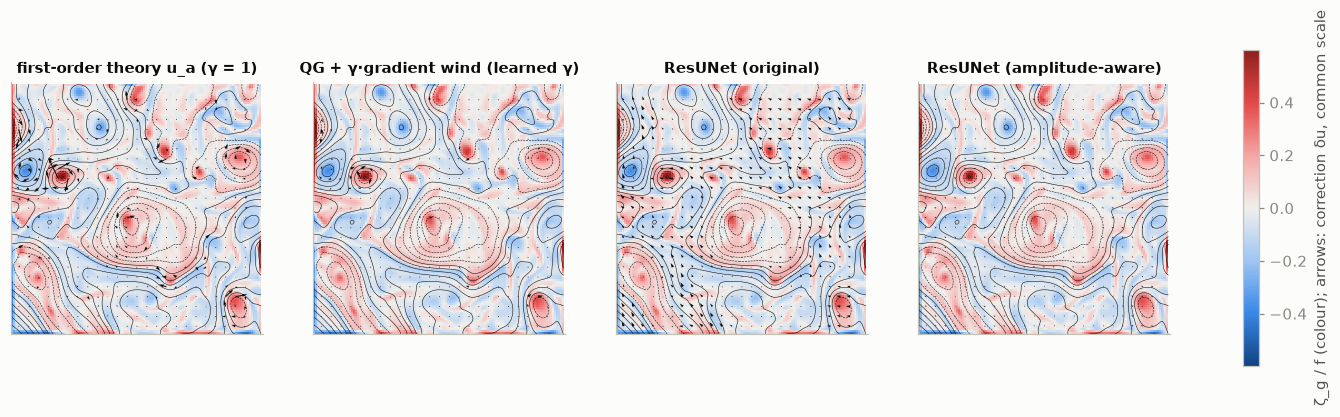

In [10]:
day_i = 10
h0 = data["ssh"][test[day_i]]
d0 = L.diagnostics(h0, grd)
corr = {k: L.correction_fields(models[k], case, h0) for k in MODEL_NAMES}
corr["theory"] = (d0["ageo_u"], d0["ageo_v"])
fig, axes = plt.subplots(1, 4, figsize=(17, 4.4))
step = 5
J, I = np.meshgrid(np.arange(grd.nx), np.arange(grd.ny))
sl = (slice(4, -4, step), slice(4, -4, step))
speed_max = max(np.nanpercentile(np.hypot(*corr[k]), 99) for k in ("resunet_amp", "resunet_orig", "theory"))
for ax, k, title in zip(axes, ["theory", "gradwind_gamma", "resunet_orig", "resunet_amp"],
                        ["first-order theory u_a (γ = 1)", "QG + γ·gradient wind (learned γ)",
                         "ResUNet (original)", "ResUNet (amplitude-aware)"]):
    cu, cv = corr[k]
    alpha = L.along_stream_fraction(cu, cv, d0["ug"], d0["vg"])
    im = ax.pcolormesh(d0["zeta"] / d0["f"], cmap=DIVERGING, norm=TwoSlopeNorm(0, -0.6, 0.6), shading="auto")
    ax.contour(h0, 12, colors=INK, linewidths=0.35)
    ax.quiver(J[sl], I[sl], cu[sl], cv[sl], color=INK, scale=speed_max * 18, width=0.004)
    ax.set_title(title, fontsize=10)
    ax.set_aspect("equal")
    ax.set_xticks([]); ax.set_yticks([])
    ax.grid(False)
fig.colorbar(im, ax=axes, shrink=0.85, label="ζ_g / f (colour); arrows: correction δu, common scale")
plt.show()

/var/folders/fh/hzjykwm53hqdtqwhsjzmjwtw0000gn/T/ipykernel_88480/124564502.py:53: RuntimeWarning: Mean of empty slice
  m = np.nanmean(mags, axis=0)


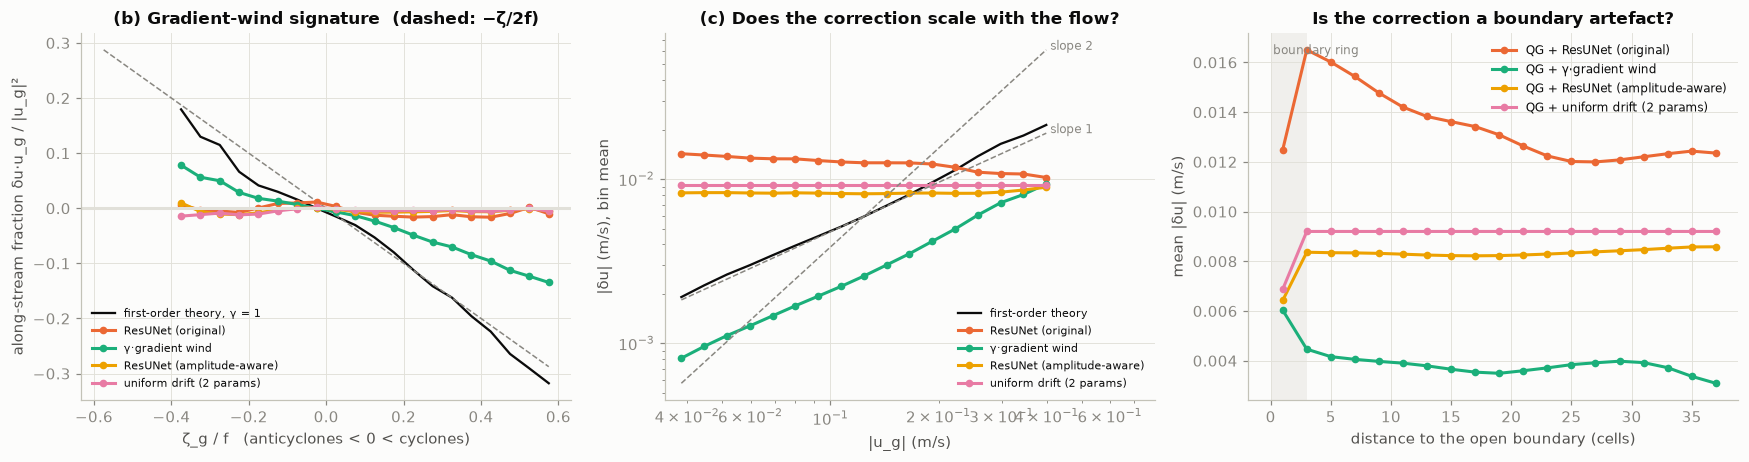

Decomposition of the learned correction (test days, cells >= 8 from the boundary)

  QG + ResUNet (original): uniform drift (-0.86, +0.64) cm/s carries 57% of the correction's mean square; the remainder:
    u_g (rescaling)                            explains   0.8% of its variance
    k x u_g (cross-stream)                     explains   0.1% of its variance
    lap u_g (viscosity)                        explains   0.2% of its variance
    (1/f) k x (u_g.grad)u_g (gradient wind)    explains   1.0% of its variance
    all four                                   explains   3.0% of its variance

  QG + ResUNet (amplitude-aware): uniform drift (-0.61, +0.42) cm/s carries 78% of the correction's mean square; the remainder:
    u_g (rescaling)                            explains   0.2% of its variance
    k x u_g (cross-stream)                     explains   0.1% of its variance
    lap u_g (viscosity)                        explains   0.2% of its variance
    (1/f) k x (u_g.grad)u_g (gradie

In [11]:
samples = {k: L.correction_samples(models[k], case, test) for k in MODEL_NAMES}
th = samples["resunet_amp"]   # the geostrophic fields are the same in every sample set
speed2 = th["ug"] ** 2 + th["vg"] ** 2
fast = speed2 > np.percentile(speed2, 25)
edges = np.linspace(-0.6, 0.6, 25)
centres = 0.5 * (edges[1:] + edges[:-1])

fig, axes = plt.subplots(1, 3, figsize=(16, 4.3))
ax = axes[0]
alpha_th = L.along_stream_fraction(th["ageo_u"], th["ageo_v"], th["ug"], th["vg"])
ax.plot(centres, L.binned(th["ro"][fast], alpha_th[fast], edges, speed2[fast]), color=INK, lw=1.5,
        label="first-order theory, γ = 1")
ax.plot(centres, -0.5 * centres, color=MUTED, ls="--", lw=1)
for k in MODEL_NAMES:
    s = samples[k]
    a = L.along_stream_fraction(s["du"], s["dv"], s["ug"], s["vg"])
    y = L.binned(s["ro"][fast], a[fast], edges, speed2[fast])
    ax.plot(centres, y, color=STYLE[k][0], marker="o", ms=4, label=STYLE[k][2].replace("QG + ", ""))
ax.axhline(0, color=GRID)
ax.legend(fontsize=7.5, loc="lower left")
ax.set_xlabel("ζ_g / f   (anticyclones < 0 < cyclones)")
ax.set_ylabel("along-stream fraction δu·u_g / |u_g|²")
ax.set_title("(b) Gradient-wind signature  (dashed: −ζ/2f)")

ax = axes[1]
sp = np.sqrt(speed2)
sedges = np.geomspace(np.percentile(sp, 5), np.percentile(sp, 99.5), 18)
sc = np.sqrt(sedges[1:] * sedges[:-1])
mag_th = L.binned(sp, np.hypot(th["ageo_u"], th["ageo_v"]), sedges)
ax.loglog(sc, mag_th, color=INK, lw=1.5, label="first-order theory")
for k in MODEL_NAMES:
    s = samples[k]
    y = L.binned(sp, np.hypot(s["du"], s["dv"]), sedges)
    ax.loglog(sc, y, color=STYLE[k][0], marker="o", ms=4, label=STYLE[k][2].replace("QG + ", ""))
for slope, anchor in ((1, mag_th), (2, mag_th)):
    ref = anchor[len(sc) // 2] * (sc / sc[len(sc) // 2]) ** slope
    ax.loglog(sc, ref, color=MUTED, ls="--", lw=1)
    ax.text(sc[-1], ref[-1], f" slope {slope}", color=MUTED, fontsize=8)
ax.set_xlim(sc[0] * 0.9, sc[-1] * 2)
ax.legend(fontsize=7.5, loc="lower right")
ax.set_xlabel("|u_g| (m/s)")
ax.set_ylabel("|δu| (m/s), bin mean")
ax.set_title("(c) Does the correction scale with the flow?")

ax = axes[2]
dist = L.distance_to_border((grd.ny, grd.nx))
dedges = np.arange(0, 40, 2)
for k in MODEL_NAMES:
    mags = []
    for s in test[::3]:
        cu, cv = L.correction_fields(models[k], case, data["ssh"][s])
        mags.append(np.hypot(cu, cv))
    m = np.nanmean(mags, axis=0)
    y = L.binned(dist.ravel().astype(float), np.nan_to_num(m).ravel(), dedges)
    ax.plot(0.5 * (dedges[1:] + dedges[:-1]), y, color=STYLE[k][0], marker="o", ms=4, label=STYLE[k][2])
ax.axvspan(0, 3, color="#f0efec", lw=0)
ax.text(0.2, 0.97, "boundary ring", transform=ax.get_xaxis_transform(), va="top", color=MUTED, fontsize=8)
ax.set_xlabel("distance to the open boundary (cells)")
ax.set_ylabel("mean |δu| (m/s)")
ax.set_title("Is the correction a boundary artefact?")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

print("Decomposition of the learned correction (test days, cells >= 8 from the boundary)")
for k in NETS:
    reg = L.regress_correction(samples[k])
    U, V = reg["drift"]
    print(f"\n  {STYLE[k][2]}: uniform drift ({100*U:+.2f}, {100*V:+.2f}) cm/s carries "
          f"{100*reg['drift_share']:.0f}% of the correction's mean square; the remainder:")
    for term, r in reg["terms"].items():
        print(f"    {term:42s} explains {100*r['r2']:5.1f}% of its variance")

### Is the network just a drift?

Split each network's correction, at every call, into its interior mean (a
uniform drift that may still vary from day to day) and the spatially varying
remainder, and run the solver with each part alone.

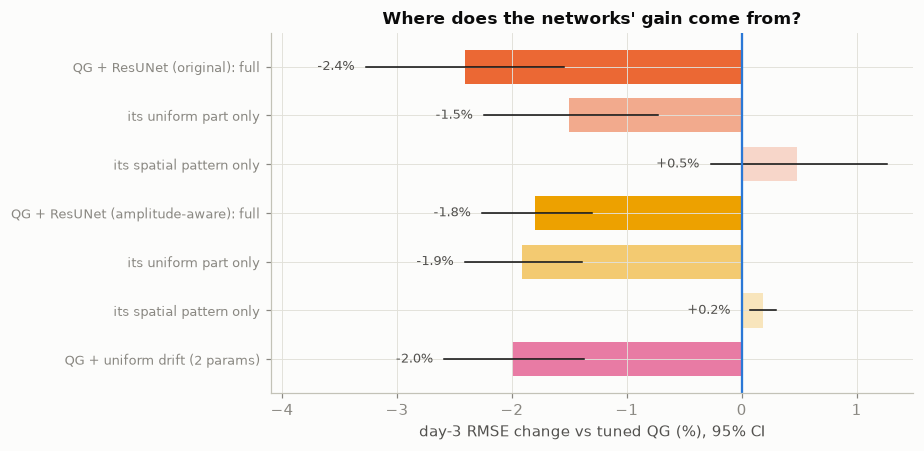

In [12]:
parts = {}
for k in NETS:
    for part in ("drift", "pattern"):
        m = L.SplitCorrection(models[k], part)
        parts[(k, part)] = np.sqrt(np.mean((L.forecast_all(case, test, m, days=3) - truth[:, :3])[..., act] ** 2, axis=-1))
fig, ax = plt.subplots(figsize=(8.5, 4.2))
base3 = rmse["qg_tuned"][:, :3]
rows = []
for k in NETS:
    rows += [(f"{STYLE[k][2]}: full", rmse[k][:, :3], STYLE[k][0], 1.0),
             (f"   its uniform part only", parts[(k, "drift")], STYLE[k][0], 0.55),
             (f"   its spatial pattern only", parts[(k, "pattern")], STYLE[k][0], 0.25)]
rows.append((STYLE["uniform_drift"][2], rmse["uniform_drift"][:, :3], STYLE["uniform_drift"][0], 1.0))
for i, (lab, r, col, a) in enumerate(rows):
    rel = 100 * (r / base3 - 1)[:, 2]
    lo, hi = L.bootstrap_ci(rel)
    ax.barh(i, rel.mean(), color=col, alpha=a, height=0.7)
    ax.plot([lo, hi], [i, i], color=INK, lw=1)
    ax.text(min(lo, 0) - 0.1, i, f"{rel.mean():+.1f}%", ha="right", va="center", fontsize=8.5, color=INK2)
ax.set_yticks(range(len(rows)), [r[0] for r in rows], fontsize=8.5)
ax.invert_yaxis()
ax.axvline(0, color=STYLE["qg_tuned"][0], lw=1.5)
ax.set_xlabel("day-3 RMSE change vs tuned QG (%), 95% CI")
ax.set_title("Where does the networks' gain come from?")
xmin = ax.get_xlim()[0]
ax.set_xlim(xmin - 0.6, max(0.5, ax.get_xlim()[1]))
fig.tight_layout()
plt.show()

### A two-parameter explanation, tested

If the networks' skill is a uniform drift, two questions decide whether it is
physics or artefact:

1. **Is it an open-boundary effect?** Rerun QG with and without the drift on a
   256×168 domain and score the same central 64×64 cells, now more than 50
   cells from any boundary instead of 32.
2. **Is it a stable property of the flow?** Map the forecast error over a grid
   of drifts (U, V), separately on training and test days: a physical drift
   has the same optimum in both.

In [13]:
U_learned, V_learned = models["uniform_drift"].uv.tolist()
drift_fixed = L.UniformDrift().to(case.dtype)
drift_fixed.uv.data = torch.tensor([U_learned, V_learned], dtype=case.dtype)
big = L.load_patch((256, 168))
print(f"{'domain':10s} {'QG RMSE day 1-3 (mm), central 64x64':38s} drift change vs QG, % [95% CI]")
for name, dat in (("128x128", data), ("256x168", big)):
    cs = L.Case(dat, c=L.C_TUNED, snu=L.SNU_TUNED)
    ny, nx = dat["ssh"].shape[1:]
    centre = np.zeros((ny, nx), bool)
    centre[ny // 2 - 32: ny // 2 + 32, nx // 2 - 32: nx // 2 + 32] = True
    tgt = L.targets_all(cs, test, days=3)
    r_qg = np.sqrt(np.mean((L.forecast_all(cs, test, days=3) - tgt)[..., centre] ** 2, axis=-1))
    r_dr = np.sqrt(np.mean((L.forecast_all(cs, test, drift_fixed, days=3) - tgt)[..., centre] ** 2, axis=-1))
    g = 100 * (r_dr / r_qg - 1)
    lo, hi = L.bootstrap_ci(g)
    print(f"{name:10s} {'  '.join(f'{1e3*v:5.2f}' for v in r_qg.mean(0)):38s} "
          + "  ".join(f"{m:+.1f} [{a:+.1f},{b:+.1f}]" for m, a, b in zip(g.mean(0), lo, hi)))

domain     QG RMSE day 1-3 (mm), central 64x64    drift change vs QG, % [95% CI]


128x128     4.57   8.31  11.96                    -3.0 [-4.2,-1.9]  -3.5 [-4.7,-2.2]  -3.5 [-4.9,-2.0]


256x168     4.57   8.32  11.96                    -3.0 [-4.2,-1.8]  -3.4 [-4.7,-2.1]  -3.5 [-4.8,-2.0]


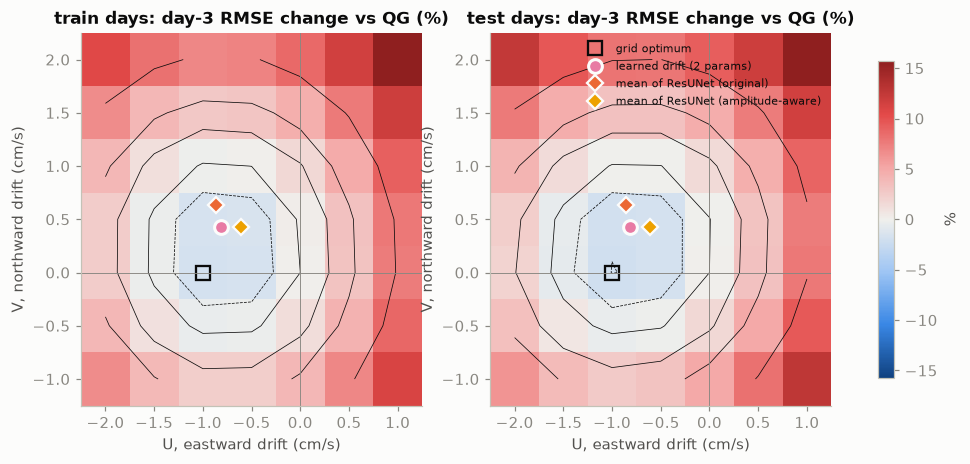

In [14]:
scan_file = L.CHECKPOINT_DIR / "drift_landscape.json"
US = np.linspace(-0.02, 0.01, 7)
VS = np.linspace(-0.01, 0.02, 7)
if scan_file.exists() and not RETRAIN:
    scan = {k: np.array(v) for k, v in json.loads(scan_file.read_text()).items()}
else:
    t0 = time.perf_counter()
    scan = {"train": L.drift_landscape(case, idx["train"][::24], US, VS),
            "test": L.drift_landscape(case, test[::3], US, VS)}
    scan_file.write_text(json.dumps({k: v.tolist() for k, v in scan.items()}))
    print(f"scan took {time.perf_counter()-t0:.0f} s")

fig, axes = plt.subplots(1, 2, figsize=(11, 4.4))
mean_drifts = {k: L.regress_correction(samples[k])["drift"] for k in NETS}
for ax, split in zip(axes, ("train", "test")):
    i0, j0 = int(np.argmin(np.abs(US))), int(np.argmin(np.abs(VS)))    # (U, V) = (0, 0): plain QG
    z = 100 * (scan[split][..., 2] / scan[split][i0, j0, 2] - 1)
    vm = np.abs(z).max()
    im = ax.pcolormesh(100 * US, 100 * VS, z.T, cmap=DIVERGING, norm=TwoSlopeNorm(0, -vm, vm), shading="nearest")
    ax.contour(100 * US, 100 * VS, z.T, levels=[-3, -2, -1, 0, 2, 4, 8], colors=INK, linewidths=0.5)
    i, j = np.unravel_index(np.argmin(z), z.shape)
    ax.plot(100 * US[i], 100 * VS[j], "s", ms=9, mfc="none", mec=INK, mew=1.5, label="grid optimum")
    ax.plot(100 * U_learned, 100 * V_learned, "o", ms=9, color=STYLE["uniform_drift"][0],
            mec="#fcfcfb", mew=2, label="learned drift (2 params)")
    for k in NETS:
        ax.plot(100 * mean_drifts[k][0], 100 * mean_drifts[k][1], "D", ms=7, color=STYLE[k][0],
                mec="#fcfcfb", mew=1.5, label=f"mean of {STYLE[k][2].replace('QG + ', '')}")
    ax.axhline(0, color=MUTED, lw=0.6); ax.axvline(0, color=MUTED, lw=0.6)
    ax.set_xlabel("U, eastward drift (cm/s)")
    ax.set_ylabel("V, northward drift (cm/s)")
    ax.set_title(f"{split} days: day-3 RMSE change vs QG (%)")
    ax.grid(False)
fig.colorbar(im, ax=axes, shrink=0.85, label="%")
axes[1].legend(fontsize=7.5, loc="upper right")
plt.show()

## 7. Conclusions

**Does it train well?** Yes, mechanically. Losses fall, validation beats tuned
QG from the first epoch, and multi-day rollouts through 216 solver steps
(3 days at `dt = 1200 s`) give finite, useful gradients. The 1-day
validation curves are noisy (47 days) and the original ResUNet was still
improving at epoch 12, so a longer run might squeeze out a little more. Any
extra skill over the 2-parameter drift is, however, not significant on this
test set.

**What did it learn?** Mostly one number: the speed at which the whole eddy
field should translate. This is an interpretable result, and a useful
diagnostic of the QG model's error, but it is not new physics:

* the 1.5-layer QG under-predicts westward eddy propagation in this region
  by about 1 cm/s;
* a network with 60 000 times more parameters than the drift found nothing
  else that generalises to the test period.

Plausible causes are what the 1.5-layer reduced-gravity model leaves out:
the barotropic / deep flow that steers eddies, topographic β, and a mean flow
that modifies baroclinic Rossby-wave speed. These are hypotheses, not tested
here.

**Caveats:**

* one 450 km box, one year of training, one seed;
* the truth is a model (degraded NATL60), fully observed;
* the test period is late summer, the least energetic season (rms Rossby
  number 0.09 vs 0.12 in training).

**Changes from the previous version of this notebook:**

* The PV-error diagnostic, the PV animation and the GIF export were removed
  in favour of the analyses above.
* Training uses `dt = 1200 s` (same QG skill as 600 s) and runs on top of the
  tuned QG.